# Dagar och helgdagar

Här undersöker vi bara hur typ av dag påverkar cykeluthyrningen: veckodag, helg och helgdag.
Vi utesluter andra faktorer så som väder.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/SeoulBikeData.csv", encoding="cp1252")

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df[df["Functioning Day"] == "Yes"].copy()

TARGET = "Rented Bike Count"
df.shape

(8465, 14)

## Skapa kalenderish
Datan har just nu bara datum och en helgdagskolumn. Vi delar därför upp den manuellt istället.

In [5]:
df["Veckodag"] = df["Date"].dt.day_of_week
df["Helg"] = df["Veckodag"] >= 5
df["Helgdag"] = df["Holiday"] == "Holiday"

df["Ledig dag"] = df["Helg"] | df["Helgdag"]

df[["Date", "Veckodag", "Helg", "Helgdag", "Ledig dag"]].head()

,Date,Veckodag,Helg,Helgdag,Ledig dag
0,2017-12-01,4,False,False,False
1,2017-12-01,4,False,False,False
2,2017-12-01,4,False,False,False
3,2017-12-01,4,False,False,False
4,2017-12-01,4,False,False,False


In [6]:
helgdagar = df[df["Helgdag"]]["Date"].dt.date.unique()
print("Antal helgdagar:", len(helgdagar))
print(helgdagar)

Antal helgdagar: 17
[datetime.date(2017, 12, 22) datetime.date(2017, 12, 24)
 datetime.date(2017, 12, 25) datetime.date(2017, 12, 31)
 datetime.date(2018, 1, 1) datetime.date(2018, 2, 15)
 datetime.date(2018, 2, 16) datetime.date(2018, 2, 17)
 datetime.date(2018, 3, 1) datetime.date(2018, 5, 1)
 datetime.date(2018, 5, 22) datetime.date(2018, 6, 6)
 datetime.date(2018, 8, 15) datetime.date(2018, 9, 23)
 datetime.date(2018, 9, 24) datetime.date(2018, 9, 25)
 datetime.date(2018, 10, 3)]


### 17 dagar av året består av röda dagar

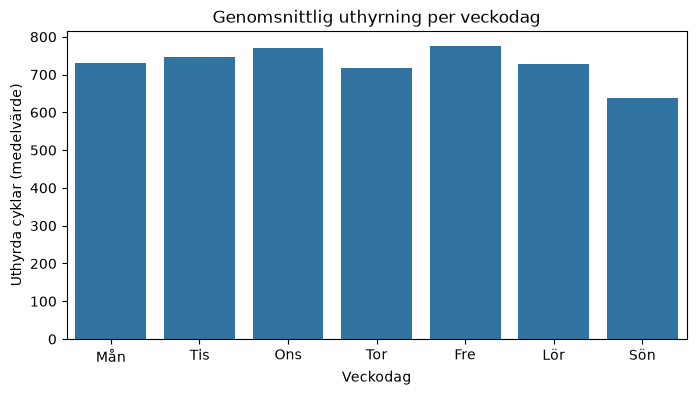

Veckodag
0    731.0
1    745.0
2    770.0
3    718.0
4    776.0
5    728.0
6    637.0
Name: Rented Bike Count, dtype: float64

In [7]:
dagnamn = ["Mån", "Tis", "Ons", "Tor", "Fre", "Lör", "Sön"]
per_dag = df.groupby("Veckodag")[TARGET].mean()

plt.figure(figsize=(8, 4))
sns.barplot(x=dagnamn, y=per_dag.values)
plt.title("Genomsnittlig uthyrning per veckodag")
plt.xlabel("Veckodag")
plt.ylabel("Uthyrda cyklar (medelvärde)")
plt.show()

per_dag.round()

**Vad syns i grafen:** Nästan alla veckodagar har en liknande mängd uthyrda cyklar. Söndag skiljer sig åt lite men det är inget större "drop".
Vi väljer därför att gå vidare för att att kolla timme för timme per veckodag.

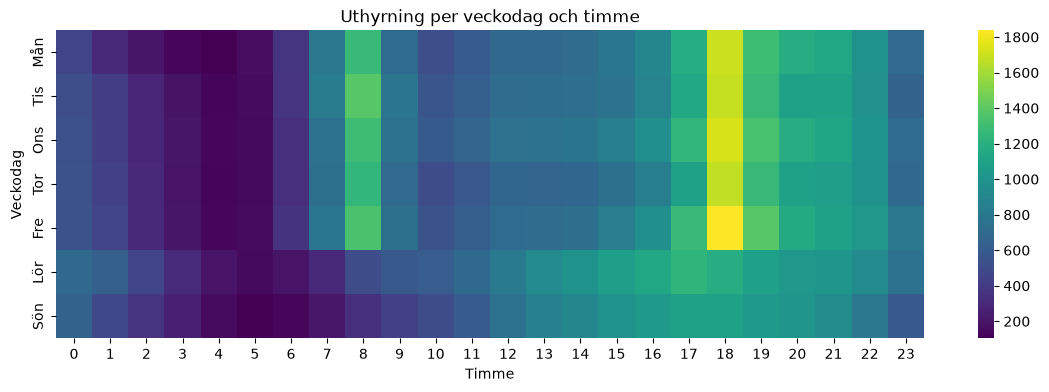

In [8]:
tabell = df.pivot_table(index="Veckodag", columns="Hour", values=TARGET, aggfunc="mean")
tabell.index = dagnamn

plt.figure(figsize=(14, 4))
sns.heatmap(tabell, cmap="viridis")
plt.title("Uthyrning per veckodag och timme")
plt.xlabel("Timme")
plt.ylabel("Veckodag")
plt.show()

**Här ser vi** att uthyrningen följer de klassiska rusningstiderna när folk tar sig till och från jobbet. Helgen är mer utspridd under dagen men lugnare på morgonen.

In [9]:
df.groupby(["Helg", "Helgdag"])[TARGET].agg(["mean", "count"]).round()

mean  count
Helg  Helgdag              
False False    756.0   5712
      True     600.0    312
True  False    698.0   2345
      True     298.0     96

**Lägst antal uthyrningar** hittar vi på helgdagar som infaller på en helg.

Dagtyp
Vanlig vardag        5712
Helg                 2345
Helgdag på vardag     312
Helgdag på helg        96
Name: count, dtype: int64


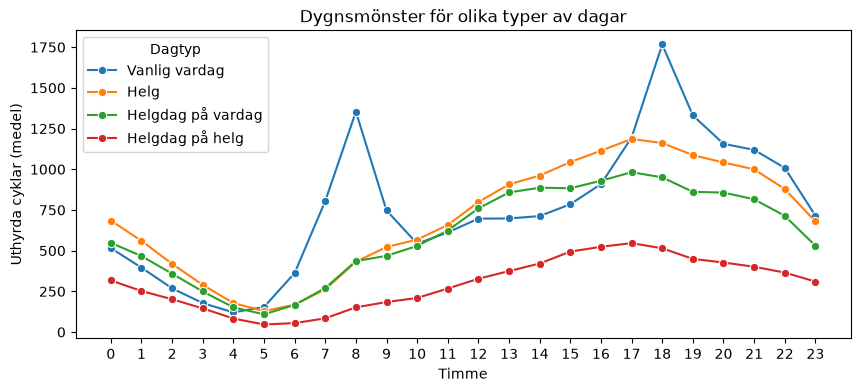

In [10]:
def dagtyp(rad):
	if rad["Helgdag"] and rad["Helg"]:
		return "Helgdag på helg"
	if rad["Helgdag"]:
		return "Helgdag på vardag"
	if rad["Helg"]:
		return "Helg"
	return "Vanlig vardag"

df["Dagtyp"] = df.apply(dagtyp, axis=1)

print(df["Dagtyp"].value_counts())

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x="Hour", y=TARGET, hue="Dagtyp", errorbar=None, marker="o")
plt.title("Dygnsmönster för olika typer av dagar")
plt.xlabel("Timme")
plt.ylabel("Uthyrda cyklar (medel)")
plt.xticks(range(0, 24))
plt.show()

**Vi ser att** helgdagar som infaller på en vardag beter sig likt en vanlig helg. Vi kan slå samman dessa värden under "ledig dag".

In [11]:
from sklearn.metrics import mean_absolute_error

# Gissning 1: bara timme
gissning_timme = df.groupby("Hour")[TARGET].transform("mean")

# Gissning 2: timme + ledig dag
gissning_ledig = df.groupby(["Hour", "Ledig dag"])[TARGET].transform("mean")

print("MAE, bara timme:        ", round(mean_absolute_error(df[TARGET], gissning_timme)))
print("MAE, timme + ledig dag: ", round(mean_absolute_error(df[TARGET], gissning_ledig)))

MAE, bara timme:         414
MAE, timme + ledig dag:  398


## Maskininlärning
Vi kommer köra en 20/80 split där 20% av datan blir testdata som inte kommer användas för upplärning

In [12]:
from sklearn.model_selection import train_test_split

X = df[["Hour", "Ledig dag"]]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Träning:", len(X_train), "rader")
print("Test:   ", len(X_test), "rader")

Träning: 6772 rader
Test:    1693 rader


## Baslinjer
Mänskliga gissningar att jämföra med. De räknas fram på **träningsdatan** (80%) och testas på
**testdatan** (20%), precis som modellerna, så att jämförelsen blir rättvis.

In [13]:
from sklearn.metrics import mean_absolute_error

gissning_medel = [y_train.mean()] * len(y_test)

tabell = pd.concat([X_train, y_train], axis=1).groupby(["Hour", "Ledig dag"])[TARGET].mean()
gissning_tabell = [tabell[(h, l)] for h, l in zip(X_test["Hour"], X_test["Ledig dag"])]

print("MAE, alltid medelvärdet:", round(mean_absolute_error(y_test, gissning_medel)))
print("MAE, tabell:            ", round(mean_absolute_error(y_test, gissning_tabell)))

MAE, alltid medelvärdet: 510
MAE, tabell:             398


**MAE, alltid medelvärdet:** gissningen är i snitt fel med 510 cyklar per timme. Det beror på att
den alltid gissar samma tal (~731), medelvärdet av alla timmar på alla dagar i träningsdatan.
Den tar ingen hänsyn till om det är natt eller rusningstid.

**MAE, tabell:** när gissningen istället slår upp medelvärdet för just den timmen och om det är
en ledig dag, sjunker felet till 398 cyklar per timme.

**Det här är de två siffrorna modellerna måste slå.**

In [14]:
from sklearn.linear_model import LinearRegression

modell_lr = LinearRegression()
modell_lr.fit(X_train, y_train)
pred_lr = modell_lr.predict(X_test)
print("MAE, linjär regression:", round(mean_absolute_error(y_test, pred_lr)))

MAE, linjär regression: 444


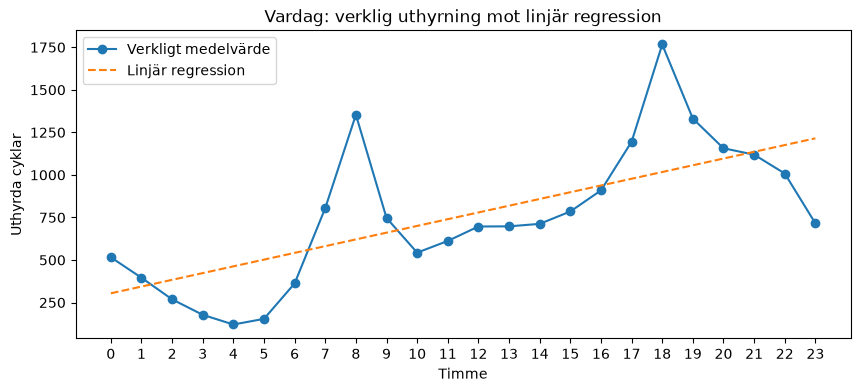

In [15]:
# Modellen gissa alla 24 timmar på en vanlig vardag
timmar = pd.DataFrame({"Hour": range(24), "Ledig dag": False})
linje = modell_lr.predict(timmar)

# Medelvärdet per timme på vardagar
verkligt = df[~df["Ledig dag"]].groupby("Hour")[TARGET].mean()

plt.figure(figsize=(10, 4))
plt.plot(verkligt.index, verkligt.values, marker="o", label="Verkligt medelvärde")
plt.plot(range(24), linje, linestyle="--", label="Linjär regression")
plt.title("Vardag: verklig uthyrning mot linjär regression")
plt.xlabel("Timme")
plt.ylabel("Uthyrda cyklar")
plt.xticks(range(0, 24))
plt.legend()
plt.show()

**Vad vi ser:** modellen är sämre än tabellen (444 mot 398). Linjär regression kan bara dra
en rak linje. Den missar morgontoppen kl 8 och tror att kl 23 är dygnets mest populära timme.
Vi behöver låta varje timme få ett eget värde istället för en rak linje.

## Optimering 1: timme som kategori
Istället för att se timme som ett tal gör vi om den till 24 ja/nej-kolumner.
Då lär sig modellen ett eget värde för varje timme.

In [16]:
X_onehot = pd.get_dummies(X, columns=["Hour"])

X_train_oh, X_test_oh, _, _ = train_test_split(X_onehot, y, test_size=0.2, random_state=42)

modell_oh = LinearRegression()
modell_oh.fit(X_train_oh, y_train)
pred_oh = modell_oh.predict(X_test_oh)

print("MAE, linjär regression med one-hot:", round(mean_absolute_error(y_test, pred_oh)))

#X_onehot.head()

MAE, linjär regression med one-hot: 409


**Resultatet** har sjunkit från 444 (felaktiga)cyklar till 409 vilket är bra. Dock vill vi få till ett bättre resultat som kan slå tabellen som fick resultatet 398.

Modellen tar hänsyn till ledig dag, men bara som ett fast tal som dras av
lika mycket varje timme.

## Optimering 2: timme och ledig dag som kombinerade kategorier
Ledig dag påverkar olika timmar olika mycket. Därför slår vi ihop timme och ledig dag
till 48 kategorier så att varje kombination får ett eget värde.


(.astype(str) gör om timme och ledig dag till text, så att de kan klistras ihop. + "_" + sätter ihop dem: 8 och False blir "8_False".)

In [17]:
X_komb = (X["Hour"].astype(str) + "_" + X["Ledig dag"].astype(str)).to_frame("Timme_ledig")
X_komb = pd.get_dummies(X_komb)

X_train_k, X_test_k, _, _ = train_test_split(X_komb, y, test_size=0.2, random_state=42)

modell_komb = LinearRegression()
modell_komb.fit(X_train_k, y_train)
pred_komb = modell_komb.predict(X_test_k)

print("MAE, linjär med kombinerade kategorier:", round(mean_absolute_error(y_test, pred_komb)))

MAE, linjär med kombinerade kategorier: 398


**Resultat:** felet sjönk från 409 till 398 cyklar per timme, lika bra som tabellen.
När varje kombination får ett eget värde räknar modellen i praktiken fram
samma medelvärden som tabellen. Med bara timme och ledig dag finns inget mer att lära sig.

## Optimering 3: Random Forest
Istället för att vi själva bygger kombinationerna testar vi en modell som hittar dem på egen hand.
Random Forest bygger många beslutsträd ("är timmen före kl 7? är det en ledig dag?")
och tar medelvärdet av deras gissningar.

In [18]:
from sklearn.ensemble import RandomForestRegressor

modell_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modell_rf.fit(X_train, y_train)
pred_rf = modell_rf.predict(X_test)

print("MAE, Random Forest:", round(mean_absolute_error(y_test, pred_rf)))

MAE, Random Forest: 398


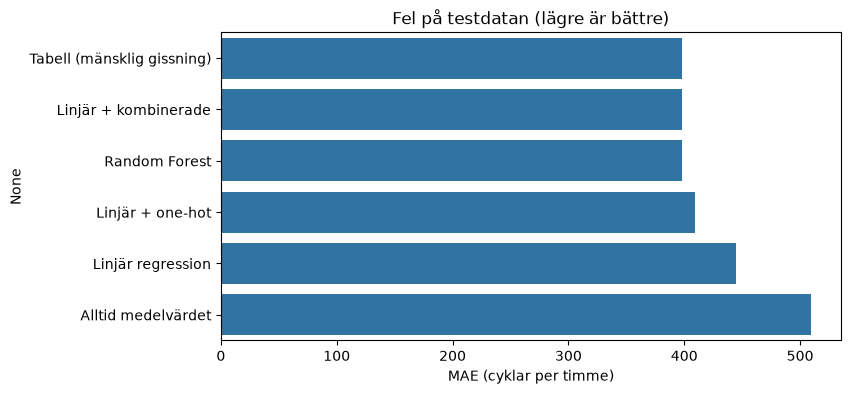

Tabell (mänsklig gissning)    398.0
Linjär + kombinerade          398.0
Random Forest                 398.0
Linjär + one-hot              409.0
Linjär regression             444.0
Alltid medelvärdet            510.0
dtype: float64

In [19]:
resultat = pd.Series({
	"Alltid medelvärdet": mean_absolute_error(y_test, gissning_medel),
	"Linjär regression": mean_absolute_error(y_test, pred_lr),
	"Linjär + one-hot": mean_absolute_error(y_test, pred_oh),
	"Linjär + kombinerade": mean_absolute_error(y_test, pred_komb),
	"Random Forest": mean_absolute_error(y_test, pred_rf),
	"Tabell (mänsklig gissning)": mean_absolute_error(y_test, gissning_tabell),
}).sort_values()

plt.figure(figsize=(8, 4))
sns.barplot(x=resultat.values, y=resultat.index)
plt.title("Fel på testdatan (lägre är bättre)")
plt.xlabel("MAE (cyklar per timme)")
plt.show()

resultat.round()

## Slutsatser

| Modell | MAE | Varför |
|---|---|---|
| Alltid medelvärdet | 510 | Vet ingenting |
| Linjär regression | 444 | Rak linje missar topparna kl 8 och 18 |
| Linjär + one-hot | 409 | Varje timme får eget värde, men ledig dag är ett enda fast tal (inte timme för timme) |
| Linjär + kombinerade | 398 | Varje timme/ledig dag-kombination får eget värde |
| Random Forest | 398 | Hittar kombinationerna själv |
| Tabell (mänsklig gissning) | 398 | Medelvärde per timme och ledig dag |

- **Optimeringarna fungerade:** felet sjönk från 444 till 398.
- **ML slår inte den mänskliga gissningen.** Med bara två features (timme | ledig dag) finns 48 kombinationer,
  och tabellen har redan det bästa svaret för varje..
- **Slutsats:** kalendern ensam räcker inte. Det återstående felet på ~400 cyklar per timme
  kan bero på andra faktorer så som vädret. Röda dagar hamnar också ofta på kallare månader vilket kan göra skillnad också.

# Del 2: Väder

In [20]:
from sklearn.metrics import root_mean_squared_error, r2_score

def utvardera(namn, y_sant, pred):
	mae = mean_absolute_error(y_sant, pred)
	rmse = root_mean_squared_error(y_sant, pred)
	r2 = r2_score(y_sant, pred)
	print(f"{namn:<35} MAE {mae:5.0f}   RMSE {rmse:5.0f}   R² {r2:.2f}")
	return {"Modell": namn, "MAE": mae, "RMSE": rmse, "R²": r2}

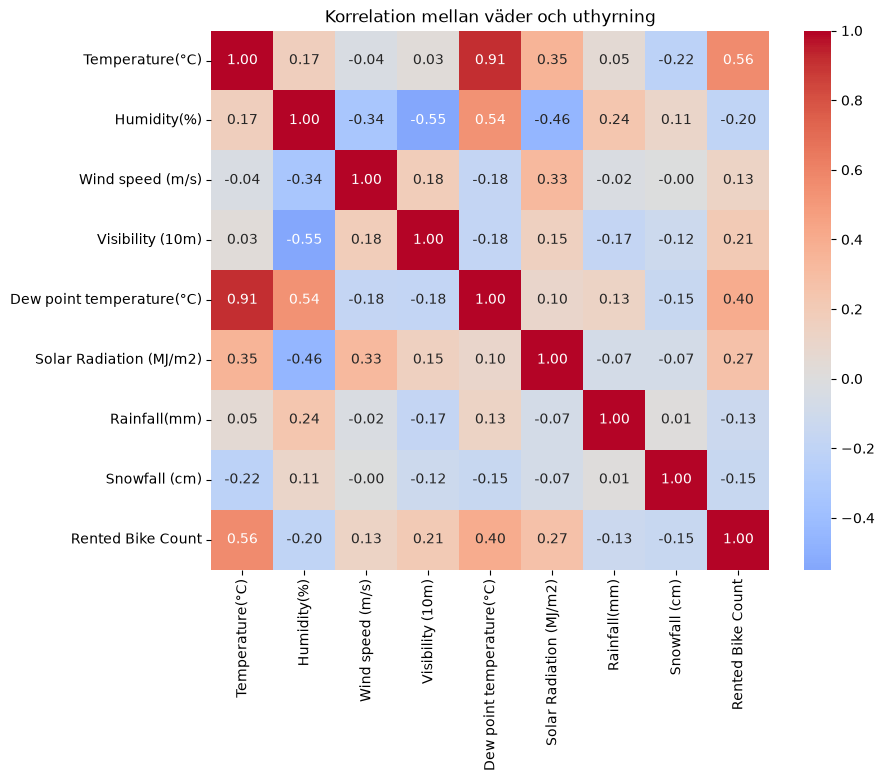

In [22]:
VADER = [
	"Temperature(°C)",
	"Humidity(%)",
	"Wind speed (m/s)",
	"Visibility (10m)",
	"Dew point temperature(°C)",
	"Solar Radiation (MJ/m2)",
	"Rainfall(mm)",
	"Snowfall (cm)",
]

plt.figure(figsize=(9, 7))
sns.heatmap(df[VADER + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korrelation mellan väder och uthyrning")
plt.show()

**Vad vi ser:** temperatur är den viktigaste väderfaktorn (0,56). Temperatur och daggpunkt är
nästan samma sak (0,91)

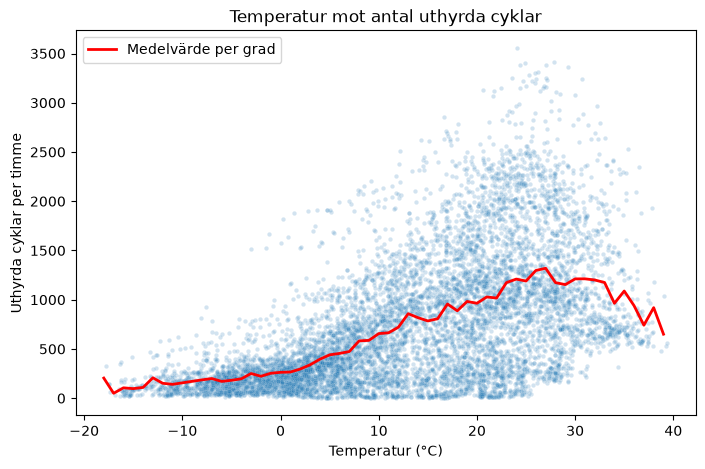

In [27]:
medel_per_grad = df.groupby(df["Temperature(°C)"].round())[TARGET].mean()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Temperature(°C)", y=TARGET, alpha=0.2, s=10)

plt.plot(medel_per_grad.index, medel_per_grad.values, color="red", linewidth=2, label="Medelvärde per grad")

plt.title("Temperatur mot antal uthyrda cyklar")
plt.xlabel("Temperatur (°C)")
plt.ylabel("Uthyrda cyklar per timme")
plt.legend()
plt.show()

**Vad vi ser:** ju varmare, desto fler cyklar, upp till ca 27°C där det planar ut.

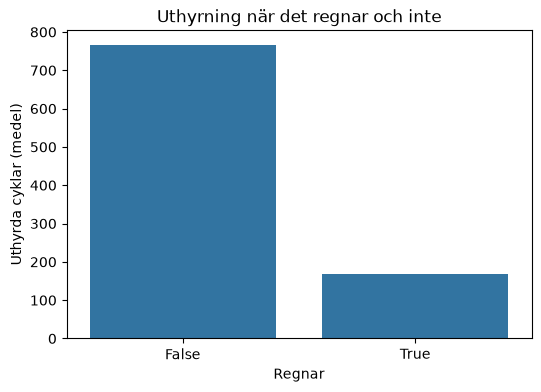

Regnar
False    766.0
True     167.0
Name: Rented Bike Count, dtype: float64

In [29]:
df["Regnar"] = df["Rainfall(mm)"] > 0

plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Regnar", y=TARGET, errorbar=None)
plt.title("Uthyrning när det regnar och inte")
plt.ylabel("Uthyrda cyklar (medel)")
plt.show()

df.groupby("Regnar")[TARGET].mean().round()

**Vad vi ser:** när det regnar hyrs bara ca 167 cyklar per timme mot ca 766 annars.
Vi skapar featuren "Regnar" (boolean).

In [31]:
X_v = df[VADER]

X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_v, y, test_size=0.2, random_state=42)

resultat_v = []
resultat_v.append(utvardera("Alltid medelvärdet", y_test_v, [y_train_v.mean()] * len(y_test_v)))

modell_lr_v = LinearRegression()
modell_lr_v.fit(X_train_v, y_train_v)
resultat_v.append(utvardera("Linjär, allt väder", y_test_v, modell_lr_v.predict(X_test_v)))

Alltid medelvärdet                  MAE   510   RMSE   627   R² -0.00
Linjär, allt väder                  MAE   349   RMSE   471   R² 0.44


## Optimering: färre och bättre väder-features
- **Ta bort daggpunkt:** Då den har stor korrelation till temperatur.
- **Lägg till Regnar:** Bättre att ha true or false istället för mängd regn.

In [32]:
VADER_OPT = [k for k in VADER if k != "Dew point temperature(°C)"] + ["Regnar"]

X_v2 = df[VADER_OPT]
X_train_v2, X_test_v2, _, _ = train_test_split(X_v2, y, test_size=0.2, random_state=42)

modell_lr_v2 = LinearRegression()
modell_lr_v2.fit(X_train_v2, y_train_v)
resultat_v.append(utvardera("Linjär, utan daggpunkt + Regnar", y_test_v, modell_lr_v2.predict(X_test_v2)))

Linjär, utan daggpunkt + Regnar     MAE   342   RMSE   464   R² 0.45


## Random Forest på väder

In [34]:
modell_rf_v = RandomForestRegressor(n_estimators=100, random_state=42)
modell_rf_v.fit(X_train_v, y_train_v)
resultat_v.append(utvardera("Random Forest, allt väder", y_test_v, modell_rf_v.predict(X_test_v)))

pd.DataFrame(resultat_v).round(2)

Random Forest, allt väder           MAE   249   RMSE   369   R² 0.65


,Modell,MAE,RMSE,R²
0,Alltid medelvärdet,509.69,626.67,-0.00
1,"Linjär, allt väder",348.92,470.64,0.44
2,"Linjär, utan daggpunkt + Regnar",341.94,464.10,0.45
3,"Random Forest, allt väder",249.29,369.43,0.65
4,"Random Forest, allt väder",249.29,369.43,0.65


## Slutsatser del 2
- **Vädret förklarar mer än kalendern:** R² 0,65 mot 0,34 i del 1.
- **Random Forest slår linjär regression tydligt** (249 mot 342), eftersom vädret har
  icke-linjära samband som en rak linje inte fångar.
- **Här slår ML den mänskliga gissningen**, till skillnad från del 1 (dag och tid).

# Del 3: Tid, dag och väder tillsammans

**Hypotes:** en slumpmässig uppdelning blandar ihop timmar från hela året. Om modellen ska förutsäga framtiden borde en kronologisk
uppdelning (träna på det tidiga, testa på det sena) ge mer realistiska siffror.

In [36]:
FEATURES = ["Hour", "Ledig dag"] + VADER_OPT
X_alla = df[FEATURES]

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_alla, y, test_size=0.2, random_state=42)

resultat_slump = []
resultat_slump.append(utvardera("Alltid medelvärdet", y_test_a, [y_train_a.mean()] * len(y_test_a)))

X_alla_oh = pd.get_dummies(X_alla, columns=["Hour"])
X_train_aoh, X_test_aoh, _, _ = train_test_split(X_alla_oh, y, test_size=0.2, random_state=42)
modell_lr_a = LinearRegression()
modell_lr_a.fit(X_train_aoh, y_train_a)
resultat_slump.append(utvardera("Linjär + one-hot", y_test_a, modell_lr_a.predict(X_test_aoh)))

modell_rf_a = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modell_rf_a.fit(X_train_a, y_train_a)
resultat_slump.append(utvardera("Random Forest", y_test_a, modell_rf_a.predict(X_test_a)))

Alltid medelvärdet                  MAE   510   RMSE   627   R² -0.00
Linjär + one-hot                    MAE   281   RMSE   371   R² 0.65
Random Forest                       MAE   114   RMSE   193   R² 0.91


## Kronologisk uppdelning
Nu tränar vi på de första 80 % av året och testar på de sista 20 %, som om vi
förutsåg framtiden.

In [39]:
# De första 80 % blir träning, de sista 20 % blir test
df_tid = df.sort_values(["Date", "Hour"])
grans = int(len(df_tid) * 0.8)
train_tid = df_tid.iloc[:grans]
test_tid = df_tid.iloc[grans:]

print("Träning:", train_tid["Date"].min().date(), "till", train_tid["Date"].max().date())
print("Test:   ", test_tid["Date"].min().date(), "till", test_tid["Date"].max().date())

X_train_t = train_tid[FEATURES]
X_test_t = test_tid[FEATURES]
y_train_t = train_tid[TARGET]
y_test_t = test_tid[TARGET]

resultat_tid = []
resultat_tid.append(utvardera("Alltid medelvärdet", y_test_t, [y_train_t.mean()] * len(y_test_t)))

X_tid_oh = pd.get_dummies(df_tid[FEATURES], columns=["Hour"])
modell_lr_t = LinearRegression()
modell_lr_t.fit(X_tid_oh.iloc[:grans], y_train_t)
resultat_tid.append(utvardera("Linjär + one-hot", y_test_t, modell_lr_t.predict(X_tid_oh.iloc[grans:])))

modell_rf_t = RandomForestRegressor(n_estimators=100, random_state=42)
modell_rf_t.fit(X_train_t, y_train_t)
pred_rf_t = modell_rf_t.predict(X_test_t)
resultat_tid.append(utvardera("Random Forest", y_test_t, pred_rf_t))

Träning: 2017-12-01 till 2018-09-11
Test:    2018-09-11 till 2018-11-30
Alltid medelvärdet                  MAE   492   RMSE   634   R² -0.12
Linjär + one-hot                    MAE   309   RMSE   402   R² 0.55
Random Forest                       MAE   244   RMSE   333   R² 0.69


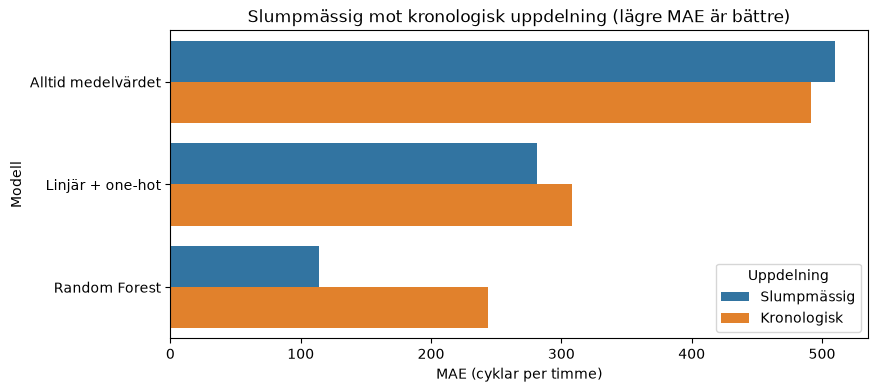

MAE                    RMSE              \
Uppdelning         Kronologisk Slumpmässig Kronologisk Slumpmässig   
Modell                                                               
Alltid medelvärdet      491.51      509.69      634.41      626.67   
Linjär + one-hot        308.55      281.42      402.24      371.30   
Random Forest           243.64      114.20      332.96      192.83   

                            R²              
Uppdelning         Kronologisk Slumpmässig  
Modell                                      
Alltid medelvärdet       -0.12       -0.00  
Linjär + one-hot          0.55        0.65  
Random Forest             0.69        0.91

In [50]:
jamfor = pd.concat([
	pd.DataFrame(resultat_slump).assign(Uppdelning="Slumpmässig"),
	pd.DataFrame(resultat_tid).assign(Uppdelning="Kronologisk"),
])

plt.figure(figsize=(9, 4))
sns.barplot(data=jamfor, x="MAE", y="Modell", hue="Uppdelning")
plt.title("Slumpmässig mot kronologisk uppdelning (lägre MAE är bättre)")
plt.xlabel("MAE (cyklar per timme)")
plt.show()

jamfor.pivot(index="Modell", columns="Uppdelning", values=["MAE", "RMSE", "R²"]).round(2)

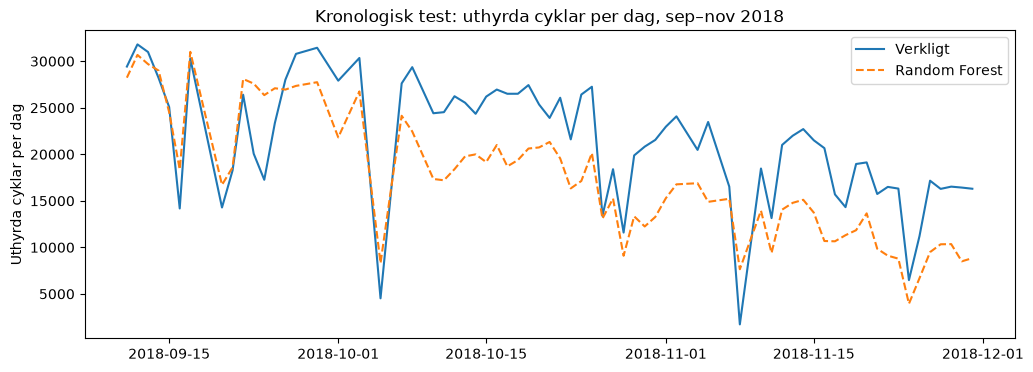

Medel i träning: 688   Medel i test: 896


In [49]:
test_dag = test_tid.assign(Prediktion=pred_rf_t).groupby("Date")[[TARGET, "Prediktion"]].sum()

plt.figure(figsize=(12, 4))
plt.plot(test_dag.index, test_dag[TARGET], label="Verkligt")
plt.plot(test_dag.index, test_dag["Prediktion"], linestyle="--", label="Random Forest")
plt.title("Kronologisk test: uthyrda cyklar per dag, sep–nov 2018")
plt.ylabel("Uthyrda cyklar per dag")
plt.legend()
plt.show()

print("Medel i träning:", round(y_train_t.mean()), "  Medel i test:", round(y_test_t.mean()))

**Vad vi ser:** modellen fångar formen (dåliga väderdagar), men gissar för lågt hela hösten.
Den har aldrig sett hösten 2018. De enda kalla perioderna den känner till är vintern
dec–mars, då uthyrningen var låg. Så när det blir kallt i oktober gissar den "vinternivå",
men i verkligheten cyklade folk mer hösten 2018. Det kan bero på att cykelsystemet
växte under året, och det finns inte med i någon av våra features.

In [43]:
for seed in [1, 2, 3, 4, 5]:
	Xa, Xb, ya, yb = train_test_split(X_alla, y, test_size=0.2, random_state=seed)
	m = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
	m.fit(Xa, ya)
	print("random_state", seed, "→ MAE", round(mean_absolute_error(yb, m.predict(Xb))))

random_state 1 → MAE 116
random_state 2 → MAE 113
random_state 3 → MAE 119
random_state 4 → MAE 120
random_state 5 → MAE 114


## Slutsatser del 3

| | Slumpmässig | Kronologisk |
|---|---|---|
| Random Forest MAE | 114 | 244 |
| Random Forest R² | 0,91 | 0,69 |

**Hypotesen stämde delvis.** Vi trodde att den kronologiska uppdelningen skulle ge mer
pålitliga siffror för att förutsäga framtiden, och det gör den. Men "pålitlig" betyder här
**sämre**, inte bättre:

1. **Den slumpmässiga uppdelningen är för optimistisk.** Timmar bredvid varandra är nästan
   likadana, så modellen har i praktiken redan sett svaren i testdatan (MAE 114).
   Siffran är stabil (113–120 med olika slump), men stabilt för bra.
2. **Den kronologiska uppdelningen är ärligare.** Den visar hur modellen skulle fungera på
   verkligt okända dagar (MAE 244).
3. **Ett år data räcker inte för framtiden.** Modellen har aldrig sett en höst, och nivån
   ändrades under året. Med fler år data skulle den kronologiska modellen bli bättre.

**Ändå slår ML den mänskliga gissningen:** även kronologiskt (244) är Random Forest långt
bättre än del 1:s tabell (398). Tid + dag + väder tillsammans gör verklig skillnad.

**Ännu en hypotes:** Kronologisk uppdelning där träningsdatan sträcker sig över ett helt år kommer ge ett bättre resultat. Den bör också var mer konsistent med gissningar. Det bör vara lika rätt/fel nästan varje dag

## Hypotes 2: träningsdata från hela året
**Hypotes:** om träningsdatan täcker ett helt år, med alla årstider, blir resultatet bättre.
Felet bör också bli jämnare, alltså ungefär lika rätt eller fel nästan varje dag.

**Problem:** vi har bara ett år data, så vi kan inte träna på ett helt år och sedan testa
på nästa. **Lösning:** vi lägger var femte hel vecka som testdata. Då finns alla
årstider i träningen, men modellen testas ändå på hela veckor den aldrig sett.

**Träning:** vecka 0–3, 5–8, 10–13, 15–18 ...

**Test:** vecka 4, 9, 14, 19 ...

In [48]:
vecka = (df_tid["Date"] - df_tid["Date"].min()).dt.days // 7

test_vb = df_tid[vecka % 5 == 4]
train_vb = df_tid[vecka % 5 != 4]
print("Andel test:", round(len(test_vb) / len(df_tid) * 100), "%")

modell_rf_vb = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modell_rf_vb.fit(train_vb[FEATURES], train_vb[TARGET])
pred_rf_vb = modell_rf_vb.predict(test_vb[FEATURES])
utvardera("Random Forest, veckoblock", test_vb[TARGET], pred_rf_vb)

Andel test: 19 %
Random Forest, veckoblock           MAE   126   RMSE   200   R² 0.90


{'Modell': 'Random Forest, veckoblock',
 'MAE': 126.48682461538459,
 'RMSE': 200.20201132548402,
 'R²': 0.9020421656047994}

Spridning i dagligt fel, kronologisk: 81
Spridning i dagligt fel, veckoblock:  66


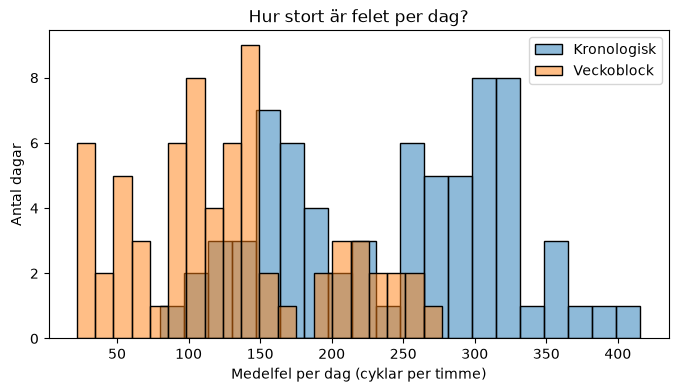

In [51]:
fel_tid = test_tid.assign(Fel=(test_tid[TARGET] - pred_rf_t).abs()).groupby("Date")["Fel"].mean()
fel_vb = test_vb.assign(Fel=(test_vb[TARGET] - pred_rf_vb).abs()).groupby("Date")["Fel"].mean()

print("Spridning i dagligt fel, kronologisk:", round(fel_tid.std()))
print("Spridning i dagligt fel, veckoblock: ", round(fel_vb.std()))

plt.figure(figsize=(8, 4))
sns.histplot(fel_tid, bins=20, alpha=0.5, label="Kronologisk")
sns.histplot(fel_vb, bins=20, alpha=0.5, label="Veckoblock")
plt.title("Hur stort är felet per dag?")
plt.xlabel("Medelfel per dag (cyklar per timme)")
plt.ylabel("Antal dagar")
plt.legend()
plt.show()

**Vad vi ser:** med veckoblock är felet både mindre och jämnare från dag till dag
(spridning 66 mot 81). Modellen är alltså mer förutsägbar när den har tränat på alla årstider.

In [52]:
# Samma tre modeller som för de andra uppdelningarna, så att jämförelsen blir rättvis
ar_test_vb = vecka % 5 == 4

resultat_vb = []
resultat_vb.append(utvardera("Alltid medelvärdet", test_vb[TARGET], [train_vb[TARGET].mean()] * len(test_vb)))

# X_tid_oh skapades i den kronologiska delen och har samma rader som df_tid
modell_lr_vb = LinearRegression()
modell_lr_vb.fit(X_tid_oh[~ar_test_vb], train_vb[TARGET])
resultat_vb.append(utvardera("Linjär + one-hot", test_vb[TARGET], modell_lr_vb.predict(X_tid_oh[ar_test_vb])))

resultat_vb.append(utvardera("Random Forest", test_vb[TARGET], pred_rf_vb))

Alltid medelvärdet                  MAE   517   RMSE   640   R² -0.00
Linjär + one-hot                    MAE   297   RMSE   391   R² 0.63
Random Forest                       MAE   126   RMSE   200   R² 0.90


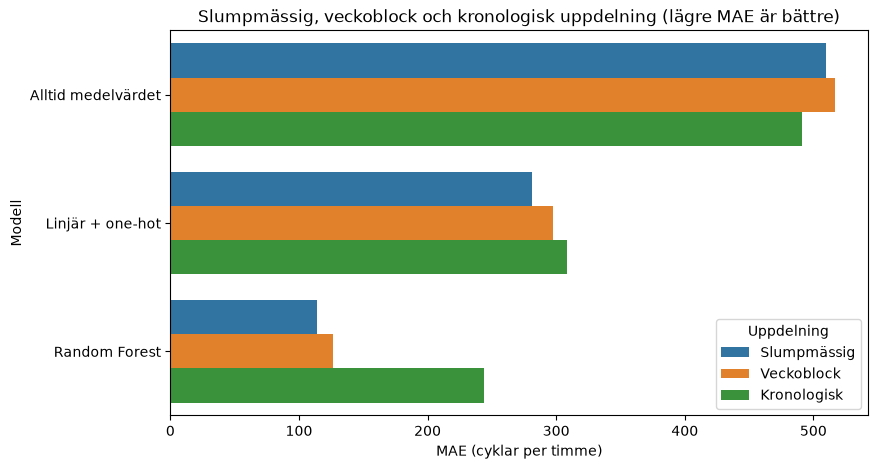

MAE                               RMSE              \
Uppdelning         Kronologisk Slumpmässig Veckoblock Kronologisk Slumpmässig   
Modell                                                                          
Alltid medelvärdet      491.51      509.69     516.55      634.41      626.67   
Linjär + one-hot        308.55      281.42     297.24      402.24      371.30   
Random Forest           243.64      114.20     126.49      332.96      192.83   

                                       R²                         
Uppdelning         Veckoblock Kronologisk Slumpmässig Veckoblock  
Modell                                                            
Alltid medelvärdet     640.03       -0.12       -0.00      -0.00  
Linjär + one-hot       390.68        0.55        0.65       0.63  
Random Forest          200.20        0.69        0.91       0.90

In [53]:
jamfor = pd.concat([
	pd.DataFrame(resultat_slump).assign(Uppdelning="Slumpmässig"),
	pd.DataFrame(resultat_vb).assign(Uppdelning="Veckoblock"),
	pd.DataFrame(resultat_tid).assign(Uppdelning="Kronologisk"),
])

plt.figure(figsize=(9, 5))
sns.barplot(data=jamfor, x="MAE", y="Modell", hue="Uppdelning")
plt.title("Slumpmässig, veckoblock och kronologisk uppdelning (lägre MAE är bättre)")
plt.xlabel("MAE (cyklar per timme)")
plt.show()

jamfor.pivot(index="Modell", columns="Uppdelning", values=["MAE", "RMSE", "R²"]).round(2)

## Slutsats hypotes 2

| Uppdelning | Träningen täcker | MAE | RMSE | R² | Spridning per dag |
|---|---|---|---|---|---|
| Kronologisk | dec–sep | 244 | 333 | 0,69 | 81 |
| Veckoblock | alla årstider | 126 | 200 | 0,90 | 66 |

**Hypotesen stämmer.** När träningsdatan täcker hela året halveras felet, och det blir
jämnare från dag till dag. Den kronologiska modellen missade för att den aldrig sett en höst.

**Begränsning:** veckoblock är inte en riktig framtidsprognos, eftersom modellen får träna
på veckor som ligger *efter* testveckorna. Den simulerar alltså "om vi hade haft ett års
historik". För att bevisa det på riktigt skulle vi behöva data från ett andra år.